# Sentiment dataset: Neural Network

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent)) 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from models.neural_network import NeuralNetwork
from utils.data import load_train
from utils.evaluation import evaluate_model, print_report, get_confusion_matrix
from utils.preprocessing import make_preprocessor

X, y = load_train("sentiment")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))

Train: (9600, 768)  Validation: (2400, 768)  Classes: 3


## Preprocessing

Scaling the features before training the model

In [3]:
rows = []
best_score = 0

for preprocessing in ["none", "standard", "standard_l2"]:
    prep = make_preprocessor(preprocessing)
    Xtr = prep.fit_transform(X_train, y_train)
    Xv = prep.transform(X_val)

    model = NeuralNetwork(
        epochs=40, lr=0.001, batch_size=128, hidden=(256, 64),
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"preprocessing": preprocessing, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_preprocessing = metrics["val_accuracy"], preprocessing

display(pd.DataFrame(rows))
print("Kept preprocessing =", best_preprocessing)

# Every later step uses the data prepared with the best preprocessing
prep = make_preprocessor(best_preprocessing)
Xtr = prep.fit_transform(X_train, y_train)
Xv = prep.transform(X_val)

,preprocessing,train_accuracy,val_accuracy,val_macro_f1
0,none,0.805312,0.677083,0.675149
1,standard,0.810417,0.663750,0.663049
2,standard_l2,0.753021,0.674167,0.672647


Kept preprocessing = none


## Network shape

Hidden layers and their width.

In [4]:
rows = []
best_score = 0

for hidden in [(64,), (256,), (256, 64), (1024,)]:
    model = NeuralNetwork(
        epochs=40, lr=0.001, batch_size=128, hidden=hidden,
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"hidden": str(hidden), **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_hidden = metrics["val_accuracy"], hidden

display(pd.DataFrame(rows))
print("Kept hidden =", best_hidden)

,hidden,train_accuracy,val_accuracy,val_macro_f1
0,"(64,)",0.769271,0.670833,0.669300
1,"(256,)",0.821354,0.677500,0.675515
2,"(256, 64)",0.805312,0.677083,0.675149
3,"(1024,)",0.795937,0.674167,0.673676


Kept hidden = (256,)


## Learning rate

The size of each step

In [5]:
rows = []
best_score = 0

for lr in [0.0001, 0.0003,0.0006, 0.001]:
    model = NeuralNetwork(
        epochs=40, lr=lr, batch_size=128, hidden=best_hidden,
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"lr": lr, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_lr = metrics["val_accuracy"], lr

display(pd.DataFrame(rows))
print("Kept lr =", best_lr)

,lr,train_accuracy,val_accuracy,val_macro_f1
0,0.0001,0.708646,0.669583,0.668246
1,0.0003,0.730313,0.670417,0.667531
2,0.0006,0.770521,0.673750,0.673369
3,0.0010,0.821354,0.677500,0.675515


Kept lr = 0.001


## Dropout

The fraction of hidden neurons switched off at random only during training

In [6]:
rows = []
best_score = 0

for dropout in [0.3, 0.5, 0.7]:
    model = NeuralNetwork(
        epochs=40, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=dropout, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"dropout": dropout, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_dropout = metrics["val_accuracy"], dropout

display(pd.DataFrame(rows))
print("Kept dropout =", best_dropout)

,dropout,train_accuracy,val_accuracy,val_macro_f1
0,0.3,0.821354,0.677500,0.675515
1,0.5,0.793229,0.679167,0.677520
2,0.7,0.741667,0.672083,0.669186


Kept dropout = 0.5


## Weight decay

penalty that keeps the weights small

In [7]:
rows = []
best_score = 0

for weight_decay in [0.0001, 0.001, 0.01]:
    model = NeuralNetwork(
        epochs=40, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=best_dropout, input_dropout=0.0, weight_decay=weight_decay,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"weight_decay": weight_decay, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_weight_decay = metrics["val_accuracy"], weight_decay

display(pd.DataFrame(rows))
print("Kept weight_decay =", best_weight_decay)

,weight_decay,train_accuracy,val_accuracy,val_macro_f1
0,0.0001,0.800521,0.674167,0.672097
1,0.0010,0.793229,0.679167,0.677520
2,0.0100,0.709688,0.665000,0.662625


Kept weight_decay = 0.001


## Input dropout

fraction of input features set to 0 at random during training

In [8]:
rows = []
best_score = 0

for input_dropout in [0.0, 0.2]:
    model = NeuralNetwork(
        epochs=40, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=best_dropout, input_dropout=input_dropout,
        weight_decay=best_weight_decay, seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"input_dropout": input_dropout, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_input_dropout = metrics["val_accuracy"], input_dropout

display(pd.DataFrame(rows))
print("Kept input_dropout =", best_input_dropout)

,input_dropout,train_accuracy,val_accuracy,val_macro_f1
0,0.0,0.793229,0.679167,0.677520
1,0.2,0.743854,0.672083,0.670087


Kept input_dropout = 0.0


## Final Model

The hyperparameters we reached, their scores, their validation accuracy per epoch.

preprocessing: none
hidden: (256,)  lr: 0.001  dropout: 0.5  weight_decay: 0.001  input_dropout: 0.0
{'train_accuracy': 0.9065625, 'val_accuracy': 0.67875, 'val_macro_f1': 0.6775676166557787}
Best epoch: 76


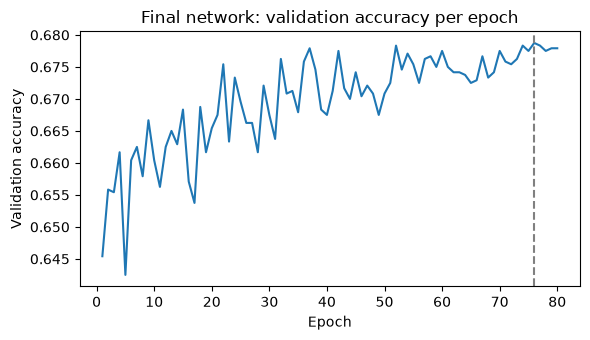

In [10]:
print("preprocessing:", best_preprocessing)
print("hidden:", best_hidden, " lr:", best_lr, " dropout:", best_dropout,
      " weight_decay:", best_weight_decay, " input_dropout:", best_input_dropout)

model = NeuralNetwork(
    epochs=80, lr=best_lr, batch_size=128, hidden=best_hidden,
    dropout=best_dropout, input_dropout=best_input_dropout,
    weight_decay=best_weight_decay, seed=42, verbose=False,
)
model.fit(Xtr, y_train, Xv, y_val)

print(evaluate_model(model, Xtr, y_train, Xv, y_val))
print("Best epoch:", model.best_epoch_)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(model.val_history) + 1), model.val_history)
plt.axvline(model.best_epoch_, linestyle="--", color="grey")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Final network: validation accuracy per epoch")
plt.tight_layout()
plt.show()

In [11]:
# Per-class results on the validation set
val_predictions = model.predict(Xv)
print_report(y_val, val_predictions)

labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)
display(pd.DataFrame(matrix,
                     index=[f"true {label}" for label in labels],
                     columns=[f"predicted {label}" for label in labels]))

              precision    recall  f1-score   support

           0       0.71      0.75      0.73       800
           1       0.60      0.57      0.59       800
           2       0.72      0.71      0.71       800

    accuracy                           0.68      2400
   macro avg       0.68      0.68      0.68      2400
weighted avg       0.68      0.68      0.68      2400



,predicted 0,predicted 1,predicted 2
true 0,603,131,66
true 1,187,460,153
true 2,64,170,566


## Final Model after playing around more

In [15]:
prep = make_preprocessor("standard")
Xtr_final = prep.fit_transform(X_train, y_train)
Xv_final = prep.transform(X_val)

final_model = NeuralNetwork(
    epochs=40,
    lr=0.0003,
    batch_size=128,
    hidden=(256,),
    dropout=0.7,
    input_dropout=0.0,
    weight_decay=0.01,
    seed=42,
    verbose=False,
)
final_model.fit(Xtr_final, y_train, Xv_final, y_val)

In [17]:
# Per-class results of the final configuration on the validation set
final_predictions = final_model.predict(Xv_final)
print_report(y_val, final_predictions)

labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, final_predictions, labels=labels)
display(pd.DataFrame(matrix,
                     index=[f"true {label}" for label in labels],
                     columns=[f"predicted {label}" for label in labels]))

              precision    recall  f1-score   support

           0       0.70      0.76      0.73       800
           1       0.61      0.57      0.59       800
           2       0.72      0.70      0.71       800

    accuracy                           0.68      2400
   macro avg       0.68      0.68      0.68      2400
weighted avg       0.68      0.68      0.68      2400



,predicted 0,predicted 1,predicted 2
true 0,610,124,66
true 1,186,459,155
true 2,72,166,562
